In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report

# Batch Gradient 

In [3]:
RANDOM_STATE=24 # in production we set rs=None it is hard to change everyware
np.random.seed(RANDOM_STATE)
rng=np.random.default_rng(seed=RANDOM_STATE)
NOISE=0.2
EPOCHS=20001
ALPHA=0.1 #LEARNING RATE
TEST_SIZE=0.2
N_SAMPLES=1000
params={
    'legend.fontsize':'medium',
    'figure.figsize':(15,6),
    'axes.labelsize':'medium',
    'axes.titlesize':'medium',
    'xtick.labelsize':'medium',  
    'ytick.labelsize':'medium',  
    
}
plt.rcParams.update(params)
CMAP=plt.cm.coolwarm
plt.style.use('seaborn-v0_8-darkgrid')

In [4]:
X,y=datasets.make_moons(
    n_samples=N_SAMPLES,
    noise=NOISE,
    random_state=RANDOM_STATE,
    shuffle=True
)


In [5]:
df=pd.DataFrame(X,columns=['A','B'])
df

,A,B
0,0.906340,0.902676
1,-1.115368,0.755793
2,1.887692,0.417597
3,-0.933450,-0.022999
4,-0.968729,0.063963
...,...,...
995,-1.005476,0.490728
996,-0.484457,0.846436
997,0.284856,0.793560
998,1.712514,-0.177786


In [6]:
df['target']=y

In [7]:
df.head()

,A,B,target
0,0.906340,0.902676,0
1,-1.115368,0.755793,0
2,1.887692,0.417597,1
3,-0.933450,-0.022999,0
4,-0.968729,0.063963,0


<Axes: xlabel='A', ylabel='B'>

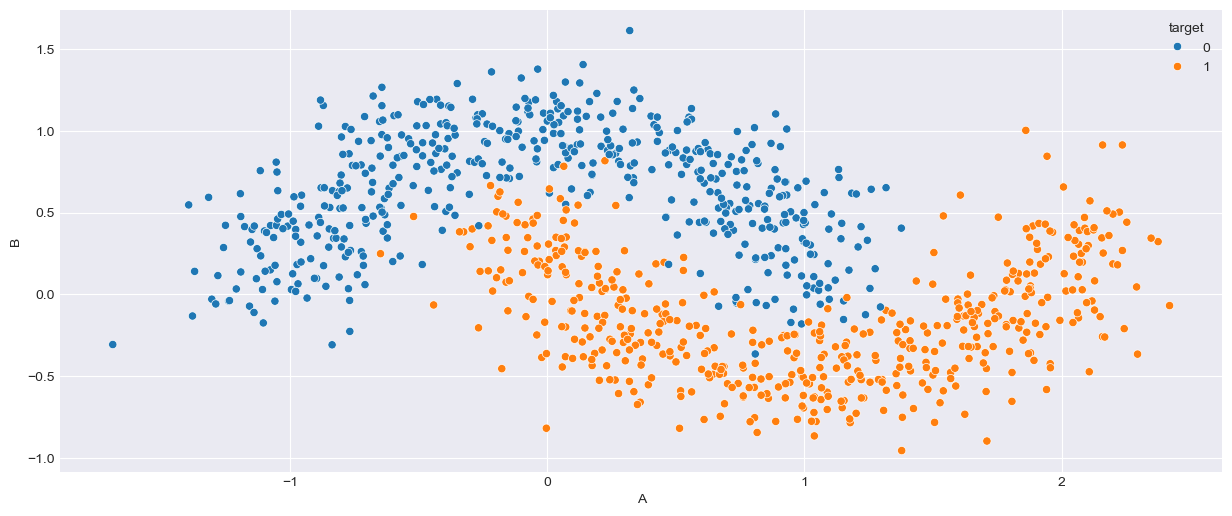

In [8]:
sns.scatterplot(data=df,x='A',y='B', hue='target')

In [9]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=TEST_SIZE,
                                               random_state=RANDOM_STATE,
                                               stratify=y)

In [10]:
def sigmoid(z):
    return 1/(1+np.exp(-z))


In [11]:
def predict(W:np.ndarray, X:np.ndarray ,b: np.ndarray):
    
    z= X.dot(W)+b
    y_pred=sigmoid(z)

    return y_pred

    

In [12]:

def train_weights(X:np.ndarray, y:np.ndarray,n_neurons=2,n_epoch=5000, learning_rate=0.02):


    np.random.seed(24)

    W=np.random.random((X.shape[1],1))
    b=np.random.random((1,1))

    minloss=float('inf')
    weights_bias=None
    y=y.reshape(-1,1)
    for i in range(n_epoch):

        error=[]

        #forward propagation
        z= X.dot(W)+b
        y_pred=sigmoid(z)

        # backward propagation
        error=y_pred-y

        #layer 1
        dl = X.T.dot(error)/len(X)

        W= W - learning_rate*dl

        # bias update:
        b = b - learning_rate*np.mean(error)
        
        if i % 100 == 0:

            eps = 1e-15
            loss = -np.mean(
                y * np.log(y_pred + eps) +
                (1-y) * np.log(1-y_pred + eps)
            )
            if loss < minloss:
                minloss=loss
                weights_bias=(W,b)

            print(f"Epoch: {i}, Loss: {loss:.4f}")


    return weights_bias








In [13]:
weights_bias=train_weights(X_train,y_train)
print(weights_bias)

Epoch: 0, Loss: 0.9402
Epoch: 100, Loss: 0.6821
Epoch: 200, Loss: 0.5508
Epoch: 300, Loss: 0.4836
Epoch: 400, Loss: 0.4449
Epoch: 500, Loss: 0.4195
Epoch: 600, Loss: 0.4013
Epoch: 700, Loss: 0.3873
Epoch: 800, Loss: 0.3762
Epoch: 900, Loss: 0.3671
Epoch: 1000, Loss: 0.3594
Epoch: 1100, Loss: 0.3529
Epoch: 1200, Loss: 0.3472
Epoch: 1300, Loss: 0.3422
Epoch: 1400, Loss: 0.3379
Epoch: 1500, Loss: 0.3340
Epoch: 1600, Loss: 0.3305
Epoch: 1700, Loss: 0.3273
Epoch: 1800, Loss: 0.3245
Epoch: 1900, Loss: 0.3219
Epoch: 2000, Loss: 0.3196
Epoch: 2100, Loss: 0.3174
Epoch: 2200, Loss: 0.3155
Epoch: 2300, Loss: 0.3137
Epoch: 2400, Loss: 0.3120
Epoch: 2500, Loss: 0.3105
Epoch: 2600, Loss: 0.3091
Epoch: 2700, Loss: 0.3078
Epoch: 2800, Loss: 0.3066
Epoch: 2900, Loss: 0.3055
Epoch: 3000, Loss: 0.3044
Epoch: 3100, Loss: 0.3035
Epoch: 3200, Loss: 0.3026
Epoch: 3300, Loss: 0.3017
Epoch: 3400, Loss: 0.3010
Epoch: 3500, Loss: 0.3002
Epoch: 3600, Loss: 0.2995
Epoch: 3700, Loss: 0.2989
Epoch: 3800, Loss: 0.298

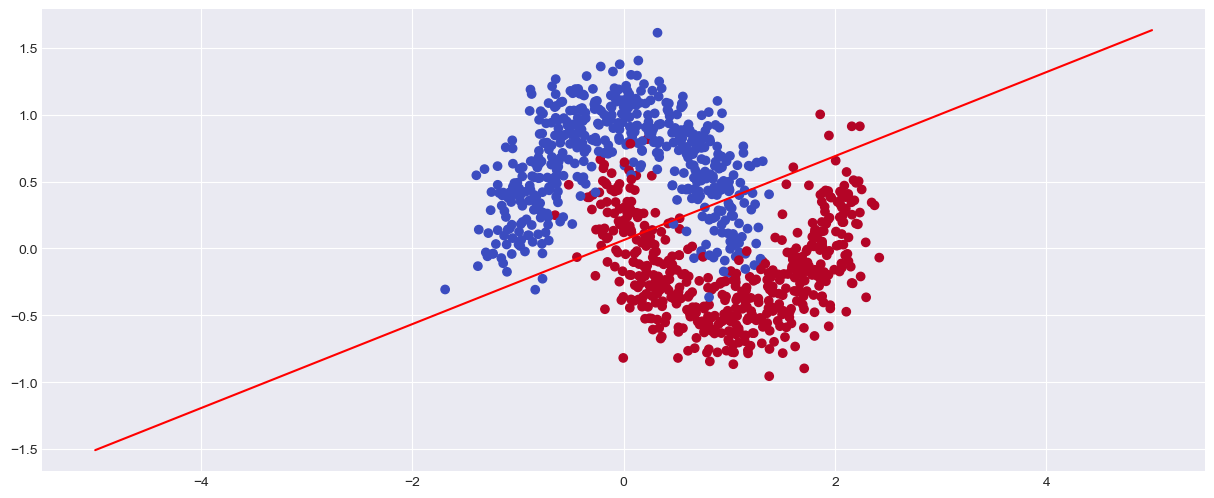

In [26]:
plt.scatter(data=df,x='A',y='B',c='target',cmap='coolwarm')




w1, w2 = weights_bias[0][0], weights_bias[0][1]
b = weights_bias[1][0]

x1 = np.linspace(-5, 5, 100)

# Decision boundary: w1*x1 + w2*x2 + b = 0
x2 = -(w1 * x1 + b) / w2

#
plt.plot(x1, x2, label='Decision Boundary', color='red')





# Predict on train data

In [22]:
predictions = []
for row in X_train:
    pred = predict(row, weights_bias[0].T,weights_bias[1])
    predictions.append(1 if pred >= 0.5 else 0)
print(f'Accuracy Score :- {round(accuracy_score(y_train, predictions) * 100,2)} %')


Accuracy Score :- 87.25 %


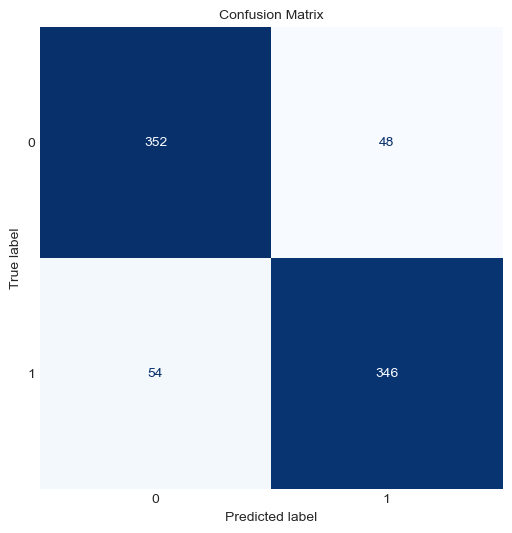

In [23]:
cm = confusion_matrix(y_train, predictions)
disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap = 'Blues', colorbar=False)
plt.title('Confusion Matrix')
plt.grid(False)
plt.show()

In [24]:
predictions = []
for row in X_test:
    pred = predict(row, weights_bias[0].T,weights_bias[1])
    predictions.append(1 if pred >= 0.5 else 0)
print(f'Accuracy Score :- {round(accuracy_score(y_test, predictions) * 100,2)} %')

Accuracy Score :- 85.0 %


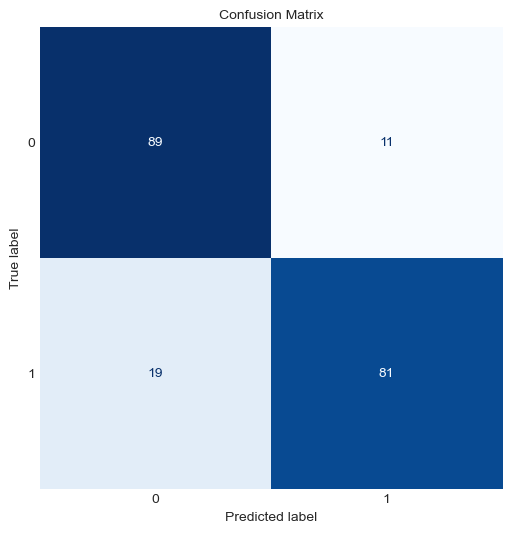

In [25]:
cm = confusion_matrix(y_test, predictions)
disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap = 'Blues', colorbar=False)
plt.title('Confusion Matrix')
plt.grid(False)
plt.show()